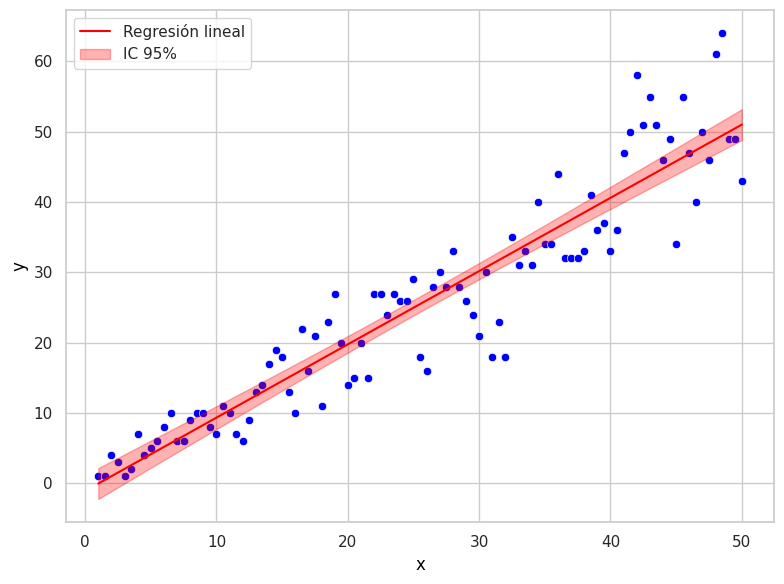

In [4]:
# Ejemplo de estabilización de varianza en Python
# Función con varianza variable

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm

# Genero datos
np.random.seed(123)
x = np.arange(1, 50.5, 0.5)
y = [np.random.poisson(lam=xi) for xi in x]

# Modelo lineal
X = sm.add_constant(x)  # Agrega término independiente
modelo = sm.OLS(y, X).fit()

# DataFrame para graficar
misdatos = pd.DataFrame({'x': x, 'y': y})

# Gráfico
sns.set(style="whitegrid")
plt.figure(figsize=(8, 6))
sns.scatterplot(x='x', y='y', data=misdatos, color='blue')

# Línea de regresión con intervalo de confianza
preds = modelo.get_prediction(X)
pred_summary = preds.summary_frame(alpha=0.05)

plt.plot(x, modelo.predict(X), color='red', label='Regresión lineal')
plt.fill_between(x, pred_summary['mean_ci_lower'], pred_summary['mean_ci_upper'],
                 color='red', alpha=0.3, label='IC 95%')

plt.xlabel("x", fontsize=12, color='black')
plt.ylabel("y", fontsize=12, color='black')
plt.legend()
plt.tight_layout()
plt.show()


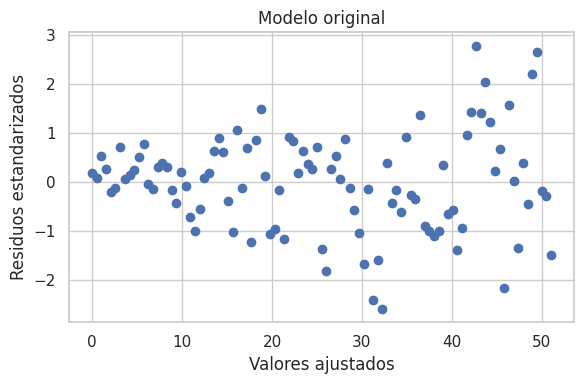

In [5]:
# Transformación de varianza
yz = np.sqrt(y)
xz = x

# Modelo lineal con datos transformados
X2 = sm.add_constant(xz)
modelo2 = sm.OLS(yz, X2).fit()

# Gráfico de residuos vs valores ajustados (modelo original)
plt.figure(figsize=(6, 4))
plt.scatter(modelo.fittedvalues, sm.OLS(y, X).fit().get_influence().resid_studentized_internal)
plt.xlabel("Valores ajustados")
plt.ylabel("Residuos estandarizados")
plt.title("Modelo original")
plt.tight_layout()
plt.show()



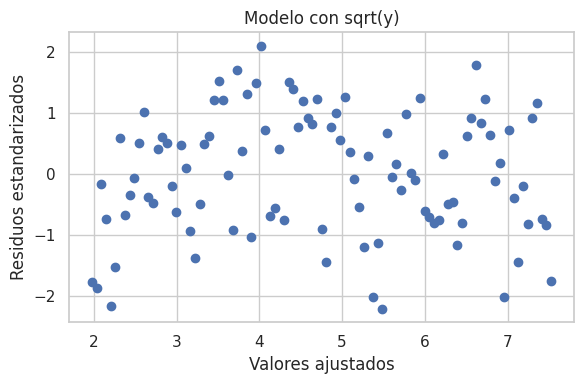

In [6]:
# Gráfico de residuos vs valores ajustados (modelo transformado)
plt.figure(figsize=(6, 4))
plt.scatter(modelo2.fittedvalues, modelo2.get_influence().resid_studentized_internal)
plt.xlabel("Valores ajustados")
plt.ylabel("Residuos estandarizados")
plt.title("Modelo con sqrt(y)")
plt.tight_layout()
plt.show()



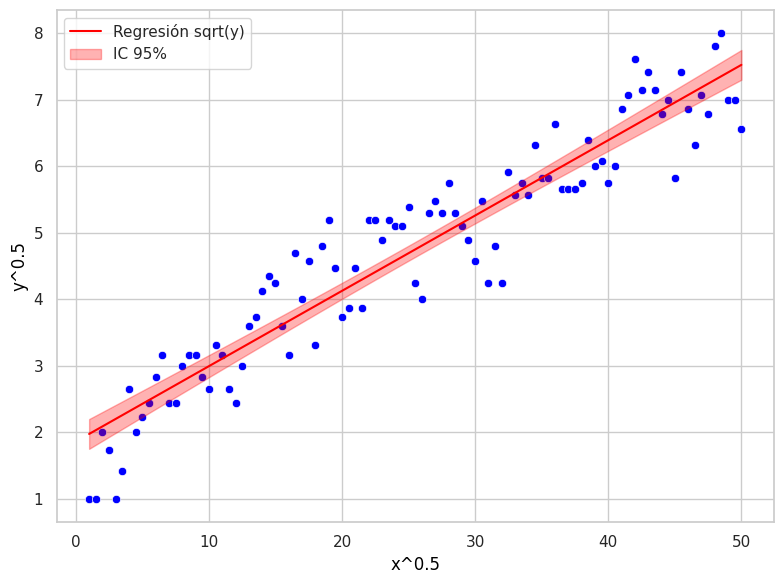

In [7]:
# Gráfico con línea de regresión y IC 95%
misdatos2 = pd.DataFrame({'xz': xz, 'yz': yz})
sns.set(style="whitegrid")
plt.figure(figsize=(8, 6))
sns.scatterplot(x='xz', y='yz', data=misdatos2, color='blue')

preds2 = modelo2.get_prediction(X2)
pred_summary2 = preds2.summary_frame(alpha=0.05)

plt.plot(xz, modelo2.predict(X2), color='red', label='Regresión sqrt(y)')
plt.fill_between(xz, pred_summary2['mean_ci_lower'], pred_summary2['mean_ci_upper'],
                 color='red', alpha=0.3, label='IC 95%')

plt.xlabel("x^0.5", fontsize=12, color='black')
plt.ylabel("y^0.5", fontsize=12, color='black')
plt.legend()
plt.tight_layout()
plt.show()



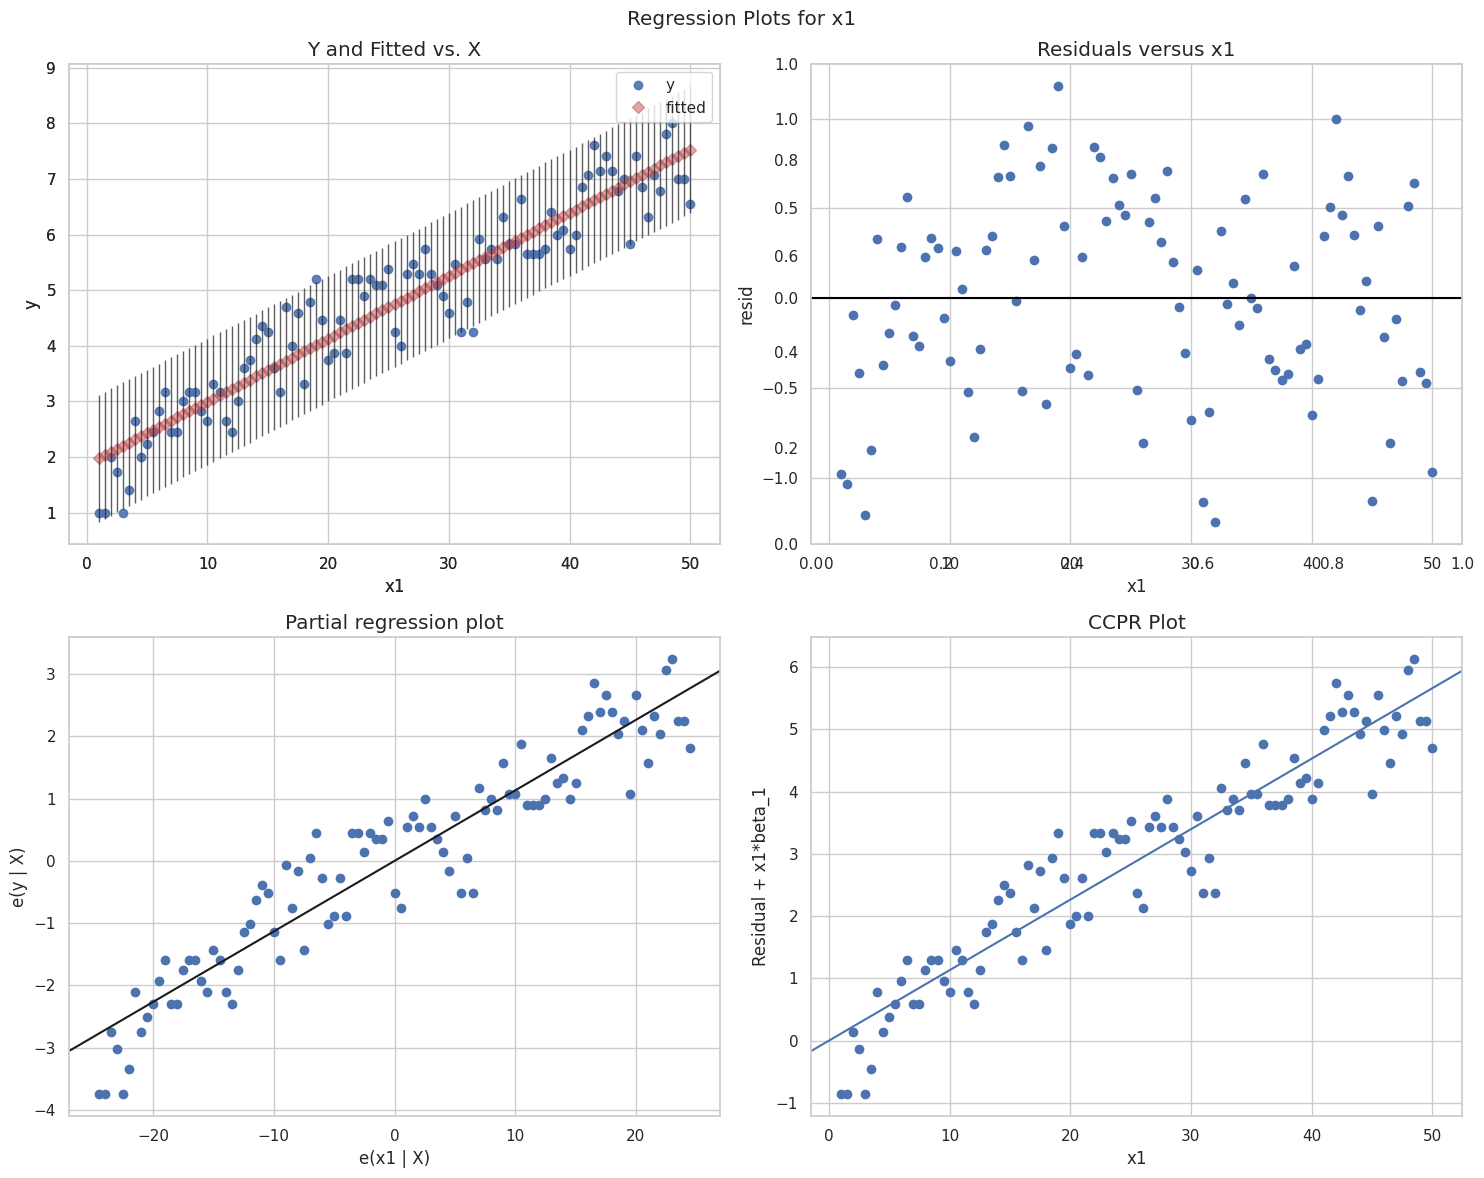

In [12]:
# Panel de diagnóstico del modelo transformado
fig = plt.figure(figsize=(15, 12))
fig.subplots_adjust(hspace=0.4, wspace=0.4)
ax1 = fig.add_subplot(2, 2, 1)
sm.graphics.plot_fit(modelo2, 1, ax=ax1)
#ax1.set_title("Ajuste del modelo")
plt.title("")

ax2 = fig.add_subplot(2, 2, 2)
sm.graphics.plot_regress_exog(modelo2, 'x1', fig=fig)#aca le tuve que cambiar el nombre a la variable 'xz' porque por defecto no lo guarda y la llama 'x1' asi que en los graficos x1=xz
plt.tight_layout()
plt.show()
